<a href="https://colab.research.google.com/github/ks148678-beep/Data-Warehousing-and-Data-Mining/blob/main/clean_loan_decision_tree6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total: 346, PAIDOFF: 260, COLLECTION: 86
Train: 242, Test: 104

===== Decision Tree =====
Accuracy : 0.692
Precision: 0.125
Recall   : 0.038
F1-Score : 0.059
AUC-ROC  : 0.636
Confusion Matrix [TN, FP; FN, TP]:
[[71  7]
 [25  1]]
              precision    recall  f1-score   support

     PAIDOFF       0.74      0.91      0.82        78
  COLLECTION       0.12      0.04      0.06        26

    accuracy                           0.69       104
   macro avg       0.43      0.47      0.44       104
weighted avg       0.59      0.69      0.63       104


===== Random Forest =====
Accuracy : 0.712
Precision: 0.250
Recall   : 0.077
F1-Score : 0.118
AUC-ROC  : 0.731
Confusion Matrix [TN, FP; FN, TP]:
[[72  6]
 [24  2]]
              precision    recall  f1-score   support

     PAIDOFF       0.75      0.92      0.83        78
  COLLECTION       0.25      0.08      0.12        26

    accuracy                           0.71       104
   macro avg       0.50      0.50      0.47       104
weight

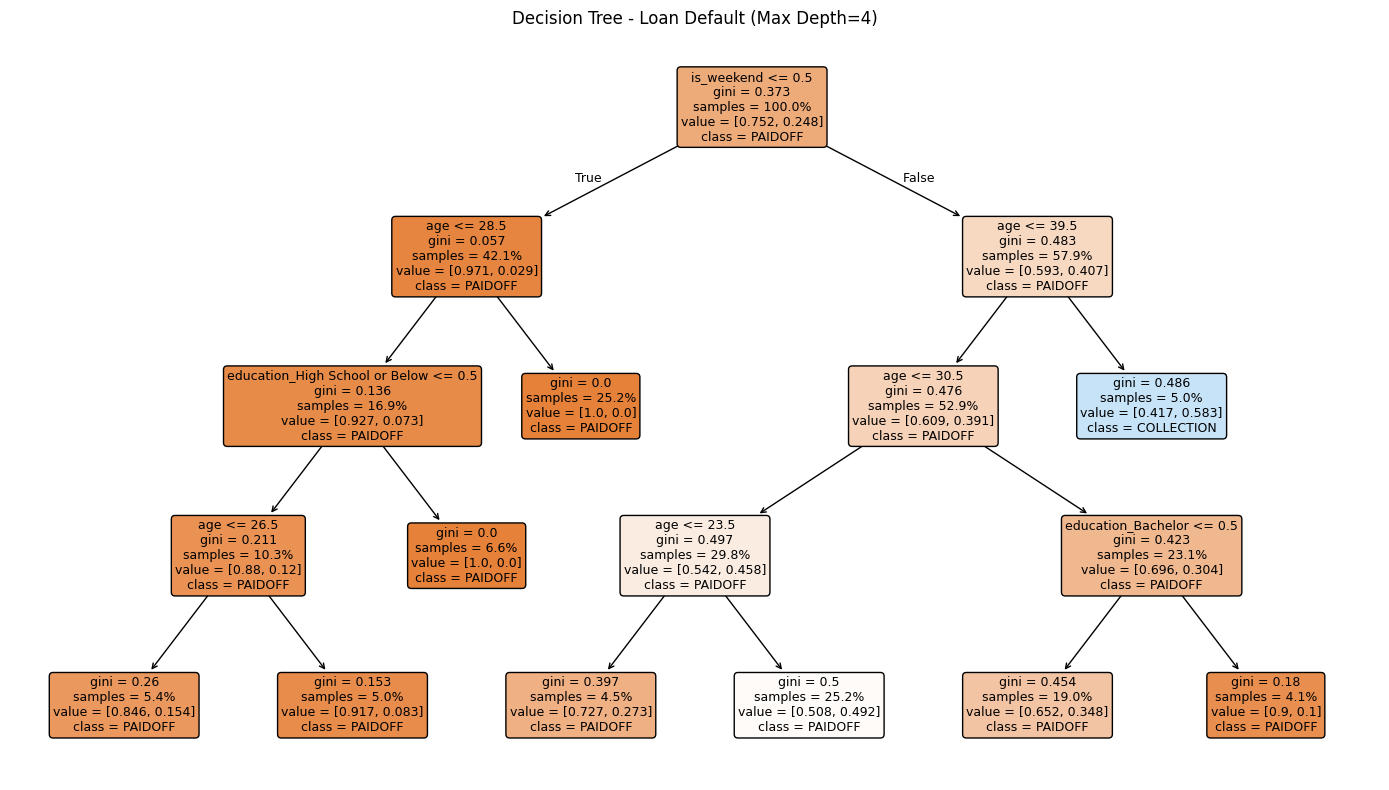

|--- is_weekend <= 0.50
|   |--- age <= 28.50
|   |   |--- education_High School or Below <= 0.50
|   |   |   |--- age <= 26.50
|   |   |   |   |--- class: 0
|   |   |   |--- age >  26.50
|   |   |   |   |--- class: 0
|   |   |--- education_High School or Below >  0.50
|   |   |   |--- class: 0
|   |--- age >  28.50
|   |   |--- class: 0
|--- is_weekend >  0.50
|   |--- age <= 39.50
|   |   |--- age <= 30.50
|   |   |   |--- age <= 23.50
|   |   |   |   |--- class: 0
|   |   |   |--- age >  23.50
|   |   |   |   |--- class: 0
|   |   |--- age >  30.50
|   |   |   |--- education_Bachelor <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- education_Bachelor >  0.50
|   |   |   |   |--- class: 0
|   |--- age >  39.50
|   |   |--- class: 1

Tree 5-Fold F1: 0.210 (+/- 0.103)
RF 5-Fold F1: 0.093 (+/- 0.089)
KNN 5-Fold F1: 0.281 (+/- 0.124)


In [3]:
"""
Loan Default Classification: Decision Tree, Random Forest, KNN
Dataset: loan_cleaned.xlsx (n=346)
Target: loan_status -> 1 = COLLECTION, 0 = PAIDOFF
"""

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. LOAD CLEANED DATA
# --------------------------------------------------
# Updated path and method to match the available file
df = pd.read_excel("/content/loan_cleaned.xlsx", parse_dates=["effective_date", "due_date"])

# Target: 1 = COLLECTION (default), 0 = PAIDOFF
df["target"] = (df["loan_status"] == "COLLECTION").astype(int)

# Features: ONLY variables known at application (NO leakage)
# Do NOT use due_date, expected_due_date, Loan_ID
features = ["age", "Principal", "terms", "Gender", "education", "is_weekend", "dayofweek"]
X = df[features]
y = df["target"]

print(f"Total: {len(df)}, PAIDOFF: {(y==0).sum()}, COLLECTION: {(y==1).sum()}")

# --------------------------------------------------
# 2. TRAIN / TEST SPLIT - STRATIFIED 70/30
# --------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

# --------------------------------------------------
# 3. PRE-PROCESSING
# --------------------------------------------------
numeric = ["age", "Principal", "terms", "is_weekend", "dayofweek"]
categorical = ["Gender", "education"]

# Tree models: only one-hot encode categoricals, no scaling needed
pre_tree = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
], remainder="passthrough")

# KNN: scale numeric + one-hot encode categoricals
pre_knn = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
])

# --------------------------------------------------
# 4. MODEL 1 - DECISION TREE
# --------------------------------------------------
tree = Pipeline([
    ("pre", pre_tree),
    ("clf", DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=10, criterion="gini", random_state=42
    ))
])
tree.fit(X_train, y_train)

# --------------------------------------------------
# 5. MODEL 2 - RANDOM FOREST
# --------------------------------------------------
rf = Pipeline([
    ("pre", pre_tree),
    ("clf", RandomForestClassifier(
        n_estimators=50, max_depth=5, random_state=42, n_jobs=-1
    ))
])
rf.fit(X_train, y_train)

# --------------------------------------------------
# 6. MODEL 3 - KNN (K=5)
# --------------------------------------------------
knn = Pipeline([
    ("pre", pre_knn),
    ("clf", KNeighborsClassifier(n_neighbors=5))
])
knn.fit(X_train, y_train)

# --------------------------------------------------
# 7. EVALUATION FUNCTION
# --------------------------------------------------
def evaluate(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    print(f"\n===== {name} =====")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
    print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
    print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
    print(f"F1-Score : {f1_score(y_test, y_pred):.3f}")
    print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba):.3f}")
    print("Confusion Matrix [TN, FP; FN, TP]:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=["PAIDOFF", "COLLECTION"]))
    return y_pred, y_proba

evaluate("Decision Tree", tree, X_test, y_test)
evaluate("Random Forest", rf, X_test, y_test)
evaluate("KNN (K=5)", knn, X_test, y_test)

# --------------------------------------------------
# 8. DRAW DECISION TREE (FOR APPENDIX)
# --------------------------------------------------
# Get feature names after one-hot encoding
cat_names = tree.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(categorical)
feature_names = list(cat_names) + numeric

plt.figure(figsize=(14, 8))
plot_tree(
    tree.named_steps["clf"],
    feature_names=feature_names,
    class_names=["PAIDOFF", "COLLECTION"],
    filled=True, rounded=True, fontsize=9, proportion=True
)
plt.title("Decision Tree - Loan Default (Max Depth=4)")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=300)
plt.show()

# Text rules for appendix
print(export_text(tree.named_steps["clf"], feature_names=feature_names))

# --------------------------------------------------
# 9. 5-FOLD CROSS-VALIDATION (OPTIONAL, FOR ROBUSTNESS)
# --------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in [("Tree", tree), ("RF", rf), ("KNN", knn)]:
    scores = cross_val_score(model, X, y, cv=cv, scoring="f1")
    print(f"{name} 5-Fold F1: {scores.mean():.3f} (+/- {scores.std():.3f})")